In [1]:
%pip install -e ..

Obtaining file:///C:/Users/V%C3%ADctorAguirreVargas/OneDrive%20-%20Kepler%20Group%20LLC/Documents/DS%26A/Data%20Science/Paycom%20Tests/Datascience-Stuff
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for datascience_toolkit (pyproject.toml): started
  Building editable for datascience_toolkit (pyproject.toml): finished with status 'done'
  Created wheel for datascience_toolkit: filename=datascience_toolkit-0.1.0-0.editable-py3-none-any.whl size=3160 sha256=5521f1514fcec1b6bbb0462bbe51038dab2518addc173cfdd2878b78f1b5d46a
  Sto


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [116]:
%load_ext autoreload
%autoreload 2

import sys

# Purgar el caché interno de datascience_toolkit para forzar la recarga de todos los submódulos e __init__.py
for mod in list(sys.modules.keys()):
    if mod.startswith("datascience_toolkit"):
        del sys.modules[mod]

import numpy as np
import pandas as pd

from datascience_toolkit import (
    DFPreprocess,
    EDAQuick,
    UnsupervisedAnalysis,
    plot_radar_comparison,
    plot_embedding_clusters,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# No supervisado

In [3]:
df = pd.read_csv("../data/VirtualPatient.csv", sep=",")

In [4]:
df.head()

,gender,age,hospitalization_three_years,ortho_hypotension,vision,audition,exhaustion_score,balance_single,gait_get_up,gait_speed_4m,grip_strength_abnormal,bmi_score,anxiety_perception,life_quality,social_visits
0,M,78,0,No,Sees moderately,Hears moderately,1,>5 sec,9.05,8.80,No,24.095500,1.3,6.8,1
1,M,79,0,No,Sees moderately,Hears moderately,1,>5 sec,10.30,6.20,No,24.205693,1.7,7.2,999
2,M,79,0,No,Sees moderately,Hears moderately,1,>5 sec,9.40,7.20,No,24.576145,2.2,6.5,1
3,M,80,0,No,Sees moderately,Hears moderately,1,>5 sec,9.20,6.45,No,24.836407,4.8,6.9,1
4,F,72,3,No,Sees well,Hears well,1,>5 sec,9.80,4.70,No,23.437500,10.0,7.3,2


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117 entries, 0 to 116
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   gender                       117 non-null    object 
 1   age                          117 non-null    int64  
 2   hospitalization_three_years  117 non-null    int64  
 3   ortho_hypotension            117 non-null    object 
 4   vision                       117 non-null    object 
 5   audition                     117 non-null    object 
 6   exhaustion_score             117 non-null    int64  
 7   balance_single               117 non-null    object 
 8   gait_get_up                  117 non-null    float64
 9   gait_speed_4m                117 non-null    float64
 10  grip_strength_abnormal       117 non-null    object 
 11  bmi_score                    117 non-null    float64
 12  anxiety_perception           117 non-null    float64
 13  life_quality        

In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,117,2,M,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,117.0,NaN,NaN,NaN,76.726496,3.478069,70.0,74.0,77.0,79.0,85.0
hospitalization_three_years,117.0,NaN,NaN,NaN,0.598291,0.831076,0.0,0.0,0.0,1.0,3.0
ortho_hypotension,117,2,No,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vision,117,3,Sees well,78,NaN,NaN,NaN,NaN,NaN,NaN,NaN
audition,117,2,Hears well,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN
exhaustion_score,117.0,NaN,NaN,NaN,1.239316,0.428501,1.0,1.0,1.0,1.0,2.0
balance_single,117,3,>5 sec,66,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gait_get_up,117.0,NaN,NaN,NaN,18.719658,91.527393,4.0,7.43,9.05,11.8,999.0
gait_speed_4m,117.0,NaN,NaN,NaN,6.619915,3.556938,2.54,4.57,5.6,7.3,22.8


In [93]:
eda = EDAQuick(df)

eda.run_eda(
    show_corr=True,
    show_outliers=True,
    show_missing=True,
    show_cardinality=True,
    show_target=False,
    show_predictive_power=False
)

Columnas convertidas a category: ['gender', 'ortho_hypotension', 'vision', 'audition', 'balance_single', 'grip_strength_abnormal']
========== DATASET INFO ==========
rows: 117
cols: 15
memory_mb: 0.01
duplicates_rows: 0
target: None
n_numeric: 9
n_categorical: 6
n_datetime: 0
n_boolean: 0
n_other: 0

========== SUMMARY (top) ==========


,dtype,n_null,pct_null,n_unique,pct_unique
feature,,,,,
bmi_score,float64,0,0.0,104,88.8889
gait_get_up,float64,0,0.0,90,76.9231
gait_speed_4m,float64,0,0.0,77,65.8120
anxiety_perception,float64,0,0.0,44,37.6068
life_quality,float64,0,0.0,34,29.0598
age,int64,0,0.0,16,13.6752
social_visits,int64,0,0.0,10,8.5470
hospitalization_three_years,int64,0,0.0,4,3.4188
vision,category,0,0.0,3,2.5641



========== MISSING VALUES ==========
No se detectaron valores faltantes.

========== CARDINALITY ==========


,feature,dtype,n_unique,pct_unique,is_constant,is_high_cardinality,is_id_like
0,bmi_score,float64,104,88.8889,False,False,False
1,gait_get_up,float64,90,76.9231,False,False,False
2,gait_speed_4m,float64,77,65.8120,False,False,False
3,anxiety_perception,float64,44,37.6068,False,False,False
4,life_quality,float64,34,29.0598,False,False,False
5,age,int64,16,13.6752,False,False,False
6,social_visits,int64,10,8.5470,False,False,False
7,hospitalization_three_years,int64,4,3.4188,False,False,False
8,vision,category,3,2.5641,False,False,False
9,balance_single,category,3,2.5641,False,False,False



========== DESCRIBE (numeric) ==========


,count,mean,std,min,25%,50%,75%,max
age,117.0,76.7265,3.4781,70.0000,74.0000,77.0000,79.0000,85.000
hospitalization_three_years,117.0,0.5983,0.8311,0.0000,0.0000,0.0000,1.0000,3.000
exhaustion_score,117.0,1.2393,0.4285,1.0000,1.0000,1.0000,1.0000,2.000
gait_get_up,117.0,18.7197,91.5274,4.0000,7.4300,9.0500,11.8000,999.000
gait_speed_4m,117.0,6.6199,3.5569,2.5400,4.5700,5.6000,7.3000,22.800
bmi_score,117.0,28.6649,5.1872,22.4793,24.7444,27.1681,29.7888,44.658
anxiety_perception,117.0,4.5778,3.1077,0.0000,2.0000,4.0000,7.9000,10.000
life_quality,117.0,8.4906,1.5308,2.0000,8.0000,8.6000,10.0000,10.000
social_visits,117.0,38.3590,181.5341,0.0000,2.0000,5.0000,7.0000,999.000



========== CORRELATION ==========


No se detectaron pares con |correlación| >= 0.80.

========== OUTLIERS ==========


,feature,n,n_outliers,pct_outliers,lower_bound,upper_bound,min,max
0,exhaustion_score,117,28,23.9316,1.0000,1.0000,1.0000,2.000
1,gait_speed_4m,117,10,8.5470,0.4750,11.3950,2.5400,22.800
2,bmi_score,117,9,7.6923,17.1777,37.3555,22.4793,44.658
3,gait_get_up,117,7,5.9829,0.8750,18.3550,4.0000,999.000
4,hospitalization_three_years,117,6,5.1282,-1.5000,2.5000,0.0000,3.000
5,social_visits,117,4,3.4188,-5.5000,14.5000,0.0000,999.000
6,life_quality,117,4,3.4188,5.0000,13.0000,2.0000,10.000
7,age,117,0,0.0000,66.5000,86.5000,70.0000,85.000
8,anxiety_perception,117,0,0.0000,-6.8500,16.7500,0.0000,10.000


,gender,age,hospitalization_three_years,ortho_hypotension,vision,audition,exhaustion_score,balance_single,gait_get_up,gait_speed_4m,grip_strength_abnormal,bmi_score,anxiety_perception,life_quality,social_visits
0,M,78,0,No,Sees moderately,Hears moderately,1,>5 sec,9.05,8.80,No,24.095500,1.3,6.8,1
1,M,79,0,No,Sees moderately,Hears moderately,1,>5 sec,10.30,6.20,No,24.205693,1.7,7.2,999
2,M,79,0,No,Sees moderately,Hears moderately,1,>5 sec,9.40,7.20,No,24.576145,2.2,6.5,1
3,M,80,0,No,Sees moderately,Hears moderately,1,>5 sec,9.20,6.45,No,24.836407,4.8,6.9,1
4,F,72,3,No,Sees well,Hears well,1,>5 sec,9.80,4.70,No,23.437500,10.0,7.3,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,F,75,0,No,Sees well,Hears well,1,<5 sec,6.30,3.80,Yes,35.430839,5.0,8.0,7
113,F,78,0,No,Sees well,Hears moderately,2,>5 sec,15.00,18.00,Yes,34.484158,8.0,9.0,7
114,F,78,0,No,Sees well,Hears moderately,1,<5 sec,12.00,15.00,Yes,35.295550,5.0,10.0,7
115,F,78,0,No,Sees well,Hears moderately,1,<5 sec,15.00,18.00,Yes,35.295550,3.0,10.0,7


In [80]:
eda.skewness_report()

,column,skewness,status,recommended_transform
0,gait_get_up,10.774,Highly Skewed,Log / Box-Cox
1,social_visits,5.192,Highly Skewed,Yeo-Johnson
2,gait_speed_4m,2.363,Highly Skewed,Log / Box-Cox
3,hospitalization_three_years,1.423,Highly Skewed,Yeo-Johnson
4,life_quality,-1.410,Highly Skewed,Log / Box-Cox
5,bmi_score,1.326,Highly Skewed,Log / Box-Cox
6,exhaustion_score,1.238,Highly Skewed,Log / Box-Cox
7,anxiety_perception,0.237,Symmetric,None
8,age,0.201,Symmetric,None


In [9]:
import inspect
from datascience_toolkit.preprocessing import DFPreprocess

print(inspect.signature(DFPreprocess.__init__))

(self, scale_num: str = 'standard', num_impute: str = 'median', cat_impute: str = 'most_frequent', encoding: str = 'ordinal')


# CLusterizacion

In [148]:
uns = UnsupervisedAnalysis(df)

prep = uns.prepare(
    scale_num="auto",
    cat_encoding="auto"
)

✓ DATA PREPARATION SUMMARY
- Filas procesadas:        117
- Columnas originales:     15
- Características finales: 23 (tras encoding)
- Estrategia de escalado:  standard
- Codificación categórica: onehot


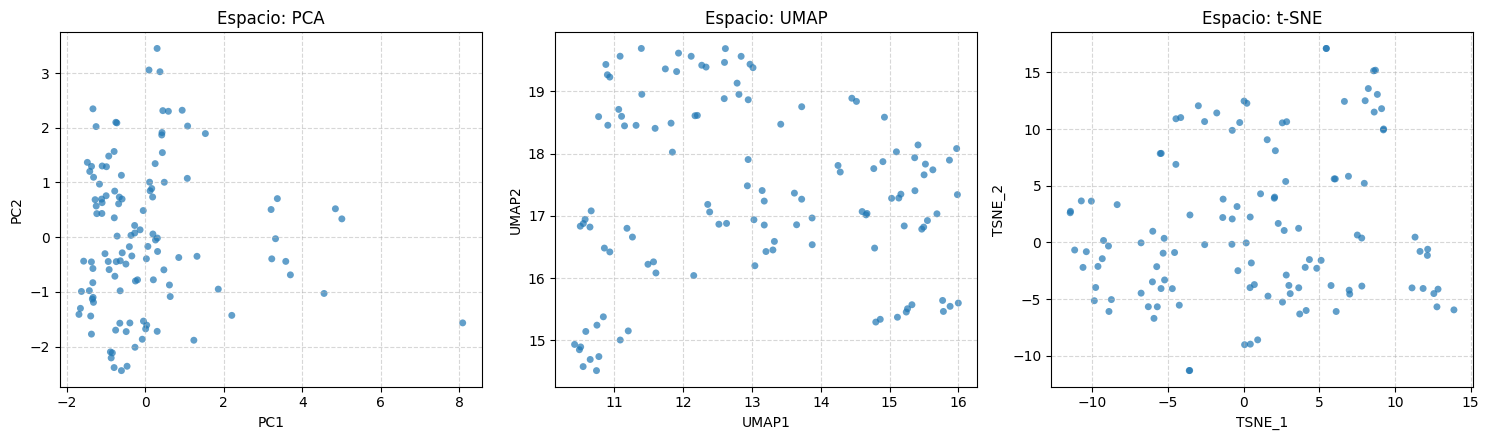

,embedding,method,n_components,variance_explained,parameters,purpose,status
0,pca_visual,pca,2,0.372765,"svd_solver=auto, whiten=False",visualization,created
1,pca_model,pca,11,0.915989,target_variance=0.9,clustering candidate,created
2,umap_visual,umap,2,NaN,"n_neighbors=15, min_dist=0.1, metric=euclidean",visualization / local structure,created


In [149]:
exploration = uns.explore(
    methods=("pca", "umap", "tsne"),
    pca_model_variance=0.90,
    umap_params={
        "n_neighbors": 15,
        "min_dist": 0.1,
        "metric": "euclidean",
    },
    tsne_params={
        "perplexity": 20,
        "learning_rate": "auto",
        "max_iter": 1000,
        "init": "pca",
        "metric": "euclidean",
    },
    plot=True,
)

exploration["report"]

In [150]:
comparison = uns.compare_spaces(
    spaces=[
        "embed",
        "pca_model",
        "umap_visual"
    ],
    method="kmeans",
    k_range=range(2, 11),
    n_init=50,
    max_iter=500,
    tol=1e-4,
    random_state=42
)

comparison["leaderboard"]


========== SPACE COMPARISON INTERPRETATION ==========
- Configuración óptima global: Espacio 'umap_visual' con k=6 (Silhouette: 0.5338, Davies-Bouldin: 0.6029).
- Espacio 'umap_visual': Mejor balance en k=6 (Silueta: 0.5338).
- Espacio 'pca_model': Mejor balance en k=2 (Silueta: 0.3844).
- Espacio 'embed': Mejor balance en k=2 (Silueta: 0.3636).


,space,method,best_k,silhouette,calinski_harabasz,davies_bouldin,inertia,n_iter,converged,consensus_rank
0,umap_visual,kmeans,6,0.533777,200.389496,0.602857,61.122101,4,True,1.0
1,pca_model,kmeans,2,0.384421,24.233537,1.390417,1015.480541,3,True,2.0
2,embed,kmeans,2,0.363597,21.891577,1.478827,1127.582441,2,True,3.0


# Vamos a comparar metodos de clustering

In [143]:
uns.available_cluster_models() #vemos que metodos tenemos, en notas sale si hace falta alguno

pd.set_option("display.max_colwidth", None)

In [151]:
recommendations = uns.recommend_cluster_models(
    X="pca_model"
)

with pd.option_context(
    "display.max_colwidth", None,
    "display.width", 200
):
    display(recommendations)

,algorithm,suitability,rationale,suggested_params
0,K-Means,Highly Recommended,Excelente línea base para 117 muestras y 11 dimensiones. Supone clústeres globulares/esféricos de varianza similar.,"k: range(2, 8), n_init=20 o 50"
1,Agglomerative (Hierarchical),Highly Recommended,Ideal para datasets pequeños a medianos (n=117). Permite descubrir jerarquías taxonómicas sin fijar k de antemano y no sufre de convergencia local.,"linkage='ward', metric='euclidean'"
2,Gaussian Mixture Models (GMM),Recommended,Permite clústeres elipsoidales con asignación probabilística suave (soft clustering). Relación muestras/variables (117/11) adecuada.,"covariance_type='diag' si d es alto, n_components: 2-6"
3,DBSCAN,Recommended,Capaz de encontrar formas no esféricas y aislar ruido/outliers. Con 11 dimensiones la distancia euclidiana aún mantiene contraste espacial.,"min_samples=11, calibrar eps con gráfica de k-distancias"
4,HDBSCAN,Recommended,Supera a DBSCAN al tolerar densidades variables y seleccionar clusters estables automáticamente a lo largo de un árbol jerárquico.,min_cluster_size=5


# Experimentos

In [152]:
experiment = uns.build_experiment(
    spaces=["embed", "pca_model"],
    models="recommended",
    k_range=range(2, 11),

    evaluate_stability=True,
    n_stability_runs=5,

    n_init=50,
    max_iter=500,
    tol=1e-4,

    #random_state=42,
    #master_seed=123
)

========== CLUSTERING EXPERIMENT PLAN ==========


,step,role,model,priority_label,available,reason,experiment_purpose
0,1,baseline,kmeans,Exploratory,True,baseline interpretable,"Establish a fast, interpretable centroid benchmark."
1,2,robust alternative,kmedoids,High,True,costo viable para este tamaño - se detectaron variables robust-scaled/outliers,Test a medoid solution that is less sensitive to extreme observations.
2,3,hierarchical alternative,agglomerative,Recommended,True,dataset pequeño/mediano,Test whether a nested or linkage-based structure better represents the sample.
3,4,probabilistic alternative,gaussian_mixture,Exploratory,True,evalúa pertenencia probabilística,Test elliptical clusters and soft membership probabilities.
4,5,density/noise diagnostic,dbscan,Caution,True,puede identificar observaciones aisladas - muestra suficiente para explorar densidad,Test irregular shapes and whether isolated observations should be treated as noise.
5,6,variable-density diagnostic,hdbscan,Exploratory,True,puede explorar densidades variables,Explore density-varying groups and noise without fixing k.


Note: this is a test plan, not a model ranking. Use plan.run() for the competition.



In [153]:
exp = experiment.plan()

with pd.option_context(
    "display.max_colwidth", None,
    "display.width", 200
):
    display(exp)


c:\Users\VíctorAguirreVargas\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
c:\Users\VíctorAguirreVargas\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
c:\Users\VíctorAguirreVargas\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
c:\Users\VíctorAguirreVargas\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `c

,role,space,model,k,silhouette,davies_bouldin,stability,strategic_rationale,next_action
0,Primary Champion,pca_model,kmeans,10,0.247192,1.039405,0.763190,"Mayor puntuación global en el torneo (Score: 17.2, Silueta: 0.2472).",Proceder a perfilamiento de arquetipos y análisis de medias por clúster.
1,Stability Champion,pca_model,kmedoids,10,0.208805,1.260810,1.000000,Máxima consistencia (ARI: 1.0000).,Usar si la reproducibilidad en producción es prioritaria sobre la separación pura.
2,Compactness Champion,pca_model,dbscan,2,0.357839,0.800328,1.000000,Mínima dispersión intra-clúster (DB: 0.8003).,Examinar fronteras de decisión y dispersión de outliers.
3,Runner-up (#4),pca_model,kmeans,9,0.229185,1.155334,0.765505,Candidato competitivo con silueta 0.2292.,Considerar como alternativa de respaldo.
4,Runner-up (#5),pca_model,kmeans,8,0.222111,1.206538,0.840926,Candidato competitivo con silueta 0.2221.,Considerar como alternativa de respaldo.


In [155]:
experiment.explain()

📊 CLUSTERING EXPERIMENT DIAGNOSIS & INTERPRETATION

1. CONFIGURACIÓN GANADORA (CHAMPION)
   - Espacio vectorial:   pca_model
   - Familia de modelo:   KMEANS
   - Número de clusters:  k = 10
   - Silhouette Score:    0.2472
   - Davies-Bouldin:      1.0394
   - Estabilidad (ARI):   0.7632


In [156]:
competition = experiment.run()

========== CLUSTERING COMPETITION ==========


,rank,space,model,params,n_clusters,silhouette,calinski_harabasz,davies_bouldin,stability_ari,noise_pct,min_cluster_pct,run_key,competition_score
0,1,pca_model,kmeans,"{'k': 10, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",10,0.247192,24.661268,1.039405,0.763190,0.0,0.854701,pca_model__kmeans__k10,17.2
1,2,pca_model,kmeans,"{'k': 9, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",9,0.229185,24.718345,1.155334,0.765505,0.0,0.854701,pca_model__kmeans__k9,18.6
2,3,pca_model,kmeans,"{'k': 8, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",8,0.222111,24.741579,1.206538,0.840926,0.0,0.854701,pca_model__kmeans__k8,19.0
3,4,pca_model,kmedoids,"{'k': 10, 'metric': 'euclidean', 'max_iter': 500, 'random_state': 42}",10,0.208805,21.960814,1.260810,1.000000,0.0,0.854701,pca_model__kmedoids__euclidean__k10,19.2
4,5,pca_model,kmeans,"{'k': 2, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",2,0.384421,24.233537,1.390417,0.905375,0.0,10.256410,pca_model__kmeans__k2,19.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,101,embed,gaussian_mixture,"{'k': 3, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",3,0.067797,6.094335,3.401115,0.633943,0.0,9.401709,embed__gaussian_mixture__diag__k3,76.8
101,102,embed,gaussian_mixture,"{'k': 7, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",7,0.072359,9.495539,2.349049,0.389653,0.0,3.418803,embed__gaussian_mixture__diag__k7,78.6
102,103,embed,gaussian_mixture,"{'k': 6, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",6,0.043037,9.346750,2.432011,0.361308,0.0,3.418803,embed__gaussian_mixture__diag__k6,80.6
103,104,embed,gaussian_mixture,"{'k': 5, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",5,0.024806,8.749562,2.699077,0.381205,0.0,0.854701,embed__gaussian_mixture__diag__k5,81.6


In [157]:
comp = competition.leaderboard()

with pd.option_context(
    "display.max_colwidth", None,
    "display.width", 200
):
    display(comp)

,rank,space,model,params,n_clusters,silhouette,calinski_harabasz,davies_bouldin,stability_ari,noise_pct,min_cluster_pct,run_key,competition_score
0,1,pca_model,kmeans,"{'k': 10, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",10,0.247192,24.661268,1.039405,0.763190,0.0,0.854701,pca_model__kmeans__k10,17.2
1,2,pca_model,kmeans,"{'k': 9, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",9,0.229185,24.718345,1.155334,0.765505,0.0,0.854701,pca_model__kmeans__k9,18.6
2,3,pca_model,kmeans,"{'k': 8, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",8,0.222111,24.741579,1.206538,0.840926,0.0,0.854701,pca_model__kmeans__k8,19.0
3,4,pca_model,kmedoids,"{'k': 10, 'metric': 'euclidean', 'max_iter': 500, 'random_state': 42}",10,0.208805,21.960814,1.260810,1.000000,0.0,0.854701,pca_model__kmedoids__euclidean__k10,19.2
4,5,pca_model,kmeans,"{'k': 2, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",2,0.384421,24.233537,1.390417,0.905375,0.0,10.256410,pca_model__kmeans__k2,19.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,101,embed,gaussian_mixture,"{'k': 3, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",3,0.067797,6.094335,3.401115,0.633943,0.0,9.401709,embed__gaussian_mixture__diag__k3,76.8
101,102,embed,gaussian_mixture,"{'k': 7, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",7,0.072359,9.495539,2.349049,0.389653,0.0,3.418803,embed__gaussian_mixture__diag__k7,78.6
102,103,embed,gaussian_mixture,"{'k': 6, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",6,0.043037,9.346750,2.432011,0.361308,0.0,3.418803,embed__gaussian_mixture__diag__k6,80.6
103,104,embed,gaussian_mixture,"{'k': 5, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",5,0.024806,8.749562,2.699077,0.381205,0.0,0.854701,embed__gaussian_mixture__diag__k5,81.6


In [158]:
comp = competition.leaderboard()

with pd.option_context(
    "display.max_colwidth", None,
    "display.width", 200
):
    display(comp)

,rank,space,model,params,n_clusters,silhouette,calinski_harabasz,davies_bouldin,stability_ari,noise_pct,min_cluster_pct,run_key,competition_score
0,1,pca_model,kmeans,"{'k': 10, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",10,0.247192,24.661268,1.039405,0.763190,0.0,0.854701,pca_model__kmeans__k10,17.2
1,2,pca_model,kmeans,"{'k': 9, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",9,0.229185,24.718345,1.155334,0.765505,0.0,0.854701,pca_model__kmeans__k9,18.6
2,3,pca_model,kmeans,"{'k': 8, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",8,0.222111,24.741579,1.206538,0.840926,0.0,0.854701,pca_model__kmeans__k8,19.0
3,4,pca_model,kmedoids,"{'k': 10, 'metric': 'euclidean', 'max_iter': 500, 'random_state': 42}",10,0.208805,21.960814,1.260810,1.000000,0.0,0.854701,pca_model__kmedoids__euclidean__k10,19.2
4,5,pca_model,kmeans,"{'k': 2, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': 42}",2,0.384421,24.233537,1.390417,0.905375,0.0,10.256410,pca_model__kmeans__k2,19.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,101,embed,gaussian_mixture,"{'k': 3, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",3,0.067797,6.094335,3.401115,0.633943,0.0,9.401709,embed__gaussian_mixture__diag__k3,76.8
101,102,embed,gaussian_mixture,"{'k': 7, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",7,0.072359,9.495539,2.349049,0.389653,0.0,3.418803,embed__gaussian_mixture__diag__k7,78.6
102,103,embed,gaussian_mixture,"{'k': 6, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",6,0.043037,9.346750,2.432011,0.361308,0.0,3.418803,embed__gaussian_mixture__diag__k6,80.6
103,104,embed,gaussian_mixture,"{'k': 5, 'covariance_type': 'diag', 'n_init': 10, 'max_iter': 500, 'random_state': 42}",5,0.024806,8.749562,2.699077,0.381205,0.0,0.854701,embed__gaussian_mixture__diag__k5,81.6


In [159]:
solution = uns.cluster_kmeans(
    X="pca_model",
    k=3,
    n_init=100,
    max_iter=1000,
    tol=1e-5,
    #random_state=42,
    name="virtual_patient_segments"
)

✓ K-MEANS SOLUTION FITTED: 'virtual_patient_segments'
- Espacio vectorial:   pca_model (11 dimensiones)
- Número de clústeres: k = 3
- Silhouette Score:    0.1743
- Davies-Bouldin:      1.7635
- Calinski-Harabasz:   23.66
- Distribución:        {0: np.int64(12), 1: np.int64(57), 2: np.int64(48)}


In [160]:
solution.summary()

,count,percentage
virtual_patient_segments,,
0,12,10.26
1,57,48.72
2,48,41.03


In [161]:
clust_df =solution.dataset()

In [162]:
clust_df['cluster'].value_counts()

cluster
1    57
2    48
0    12
Name: count, dtype: int64

In [163]:
solution.describe(top_n=5, min_abs_z=0.4)

📋 DISTINCTIVE CLUSTER PROFILES (Z-SCORE DIFFERENTIAL)

🔹 Clúster 0 (12 observaciones, 10.3%):
   ▲ gait_speed_4m             | z = +2.22 | Clúster: 14.492 (Global: 6.62)
   ▲ bmi_score                 | z = +2.10 | Clúster: 39.49 (Global: 28.665)
   ▲ exhaustion_score          | z = +1.39 | Clúster: 1.833 (Global: 1.239)
   ▲ age                       | z = +0.97 | Clúster: 80.083 (Global: 76.726)
   ▲ gait_get_up               | z = +0.90 | Clúster: 101.083 (Global: 18.72)

🔹 Clúster 1 (57 observaciones, 48.7%):
   ▼ anxiety_perception        | z = -0.79 | Clúster: 2.121 (Global: 4.578)
   ▲ life_quality              | z = +0.51 | Clúster: 9.272 (Global: 8.491)
   ▲ age                       | z = +0.46 | Clúster: 78.333 (Global: 76.726)

🔹 Clúster 2 (48 observaciones, 41.0%):
   ▲ anxiety_perception        | z = +0.81 | Clúster: 7.096 (Global: 4.578)
   ▼ age                       | z = -0.79 | Clúster: 73.979 (Global: 76.726)
   ▼ life_quality              | z = -0.56 | Clúster: 7.6

,cluster,feature,cluster_mean,global_mean,z_score,direction
0,0,gait_speed_4m,14.492,6.620,2.223,High (+)
1,0,bmi_score,39.490,28.665,2.096,High (+)
2,0,exhaustion_score,1.833,1.239,1.392,High (+)
3,0,age,80.083,76.726,0.969,High (+)
4,0,gait_get_up,101.083,18.720,0.904,High (+)
5,1,anxiety_perception,2.121,4.578,-0.794,Low (-)
6,1,life_quality,9.272,8.491,0.513,High (+)
7,1,age,78.333,76.726,0.464,High (+)
8,2,anxiety_perception,7.096,4.578,0.814,High (+)
9,2,age,73.979,76.726,-0.793,Low (-)


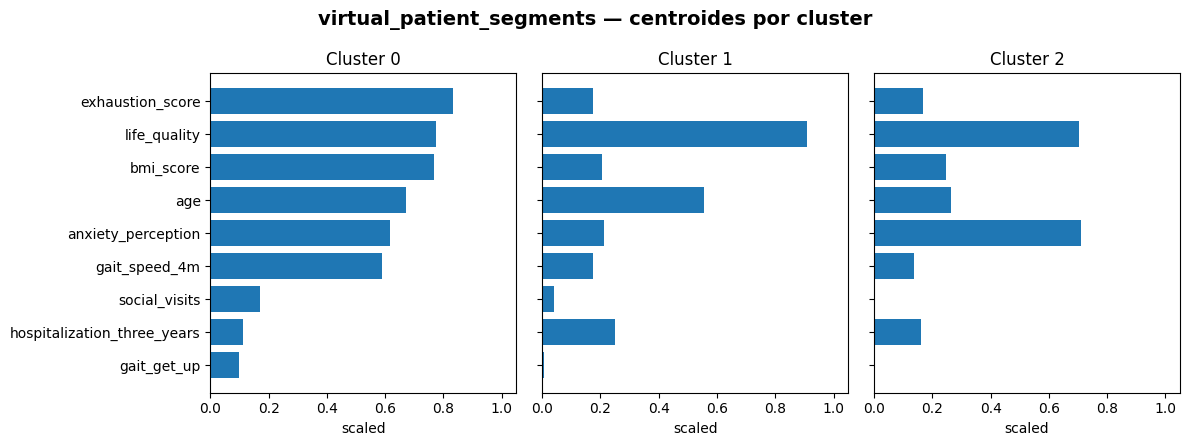

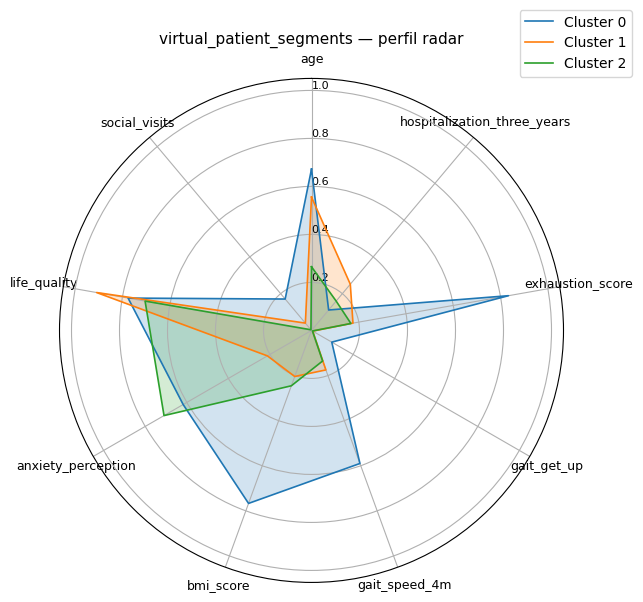

In [164]:

solution.plot_cluster_bars(normalize=True)
solution.plot_cluster_radar(normalize="minmax")

# Ejercicio nuevo

In [2]:
df = pd.read_csv("basic3.csv")

In [3]:
df.head(3)

,x,y,color
0,591.141815,339.509605,1
1,152.000000,337.000000,0
2,306.383225,304.362656,2


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5710 entries, 0 to 5709
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       5710 non-null   float64
 1   y       5710 non-null   float64
 2   color   5710 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 134.0 KB


In [5]:
df.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
x,5710.0,307.560725,161.690947,34.756985,172.650264,269.944494,441.790020,699.513371
y,5710.0,263.811323,96.234210,35.675000,188.692903,270.372780,337.014137,481.972179
color,5710.0,1.126270,0.815419,0.000000,0.000000,1.000000,2.000000,2.000000


# Strong EDA

In [6]:
eda = EDAQuick(df)

eda.run_eda(
    show_corr=True,
    show_outliers=True,
    show_missing=True,
    show_cardinality=True,
    show_target=False,
    show_predictive_power=False
)

Columnas convertidas a category: []
========== DATASET INFO ==========
rows: 5710
cols: 3
memory_mb: 0.13
duplicates_rows: 0
target: None
n_numeric: 3
n_categorical: 0
n_datetime: 0
n_boolean: 0
n_other: 0

========== SUMMARY (top) ==========


,dtype,n_null,pct_null,n_unique,pct_unique
x,float64,0,0.0000,5708,99.9600
y,float64,0,0.0000,5706,99.9300
color,int64,0,0.0000,3,0.0500



========== MISSING VALUES ==========
No se detectaron valores faltantes.

========== CARDINALITY ==========


,feature,dtype,n_unique,pct_unique,is_constant,is_high_cardinality,is_id_like
0,x,float64,5708,99.9600,False,False,True
1,y,float64,5706,99.9300,False,False,True
2,color,int64,3,0.0500,False,False,False



========== DESCRIBE (numeric) ==========


,count,mean,std,min,25%,50%,75%,max
x,5710.0000,307.5607,161.6909,34.7570,172.6503,269.9445,441.7900,699.5134
y,5710.0000,263.8113,96.2342,35.6750,188.6929,270.3728,337.0141,481.9722
color,5710.0000,1.1263,0.8154,0.0000,0.0000,1.0000,2.0000,2.0000



========== CORRELATION ==========


No se detectaron pares con |correlación| >= 0.80.

========== OUTLIERS ==========


,feature,n,n_outliers,pct_outliers,lower_bound,upper_bound,min,max
0,x,5710,0,0.0000,-231.0594,845.4997,34.7570,699.5134
1,y,5710,0,0.0000,-33.7889,559.4960,35.6750,481.9722
2,color,5710,0,0.0000,-3.0000,5.0000,0.0000,2.0000


{'category_conversion': {'converted': [], 'skipped': []},
 'dataset_info': {'rows': 5710,
  'cols': 3,
  'memory_mb': 0.13,
  'duplicates_rows': 0,
  'target': None,
  'n_numeric': 3,
  'n_categorical': 0,
  'n_datetime': 0,
  'n_boolean': 0,
  'n_other': 0},
 'summary':          dtype  n_null  pct_null  n_unique  pct_unique
 x      float64       0       0.0      5708       99.96
 y      float64       0       0.0      5706       99.93
 color    int64       0       0.0         3        0.05,
 'missing_report': Empty DataFrame
 Columns: [dtype, n_missing, pct_missing, n_present]
 Index: [],
 'cardinality_report':   feature    dtype  n_unique  pct_unique  is_constant  is_high_cardinality  \
 0       x  float64      5708       99.96        False                False   
 1       y  float64      5706       99.93        False                False   
 2   color    int64         3        0.05        False                False   
 
    is_id_like  
 0        True  
 1        True  
 2       Fals

In [7]:
eda.skewness_report()

,feature,skewness,abs_skewness,severity,flagged,recommendation
0,x,0.475838,0.475838,low,False,none required from skewness alone
1,color,-0.235420,0.235420,low,False,none required from skewness alone
2,y,-0.112302,0.112302,low,False,none required from skewness alone


In [8]:
uns = UnsupervisedAnalysis(df)

prep = uns.prepare(
    scale_num="auto",
    cat_encoding="auto"
)

========== UNSUPERVISED PREPROCESSING PLAN ==========
Numeric: {'standard': ['x', 'y', 'color'], 'robust': []}
Categorical: {}
Excluded: None
Output shape: (5710, 3)


In [9]:
import matplotlib.pyplot as plt

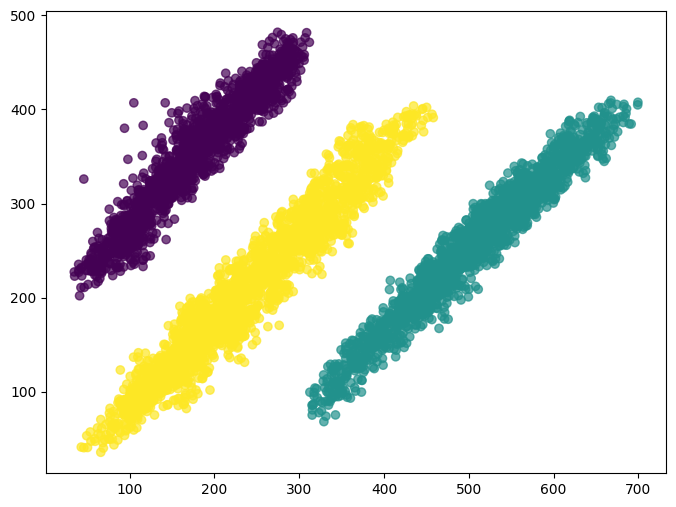

In [10]:
x= df["x"]
y = df["y"]
color = df["color"]

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(x, y, c=color, cmap='viridis', alpha=0.7)

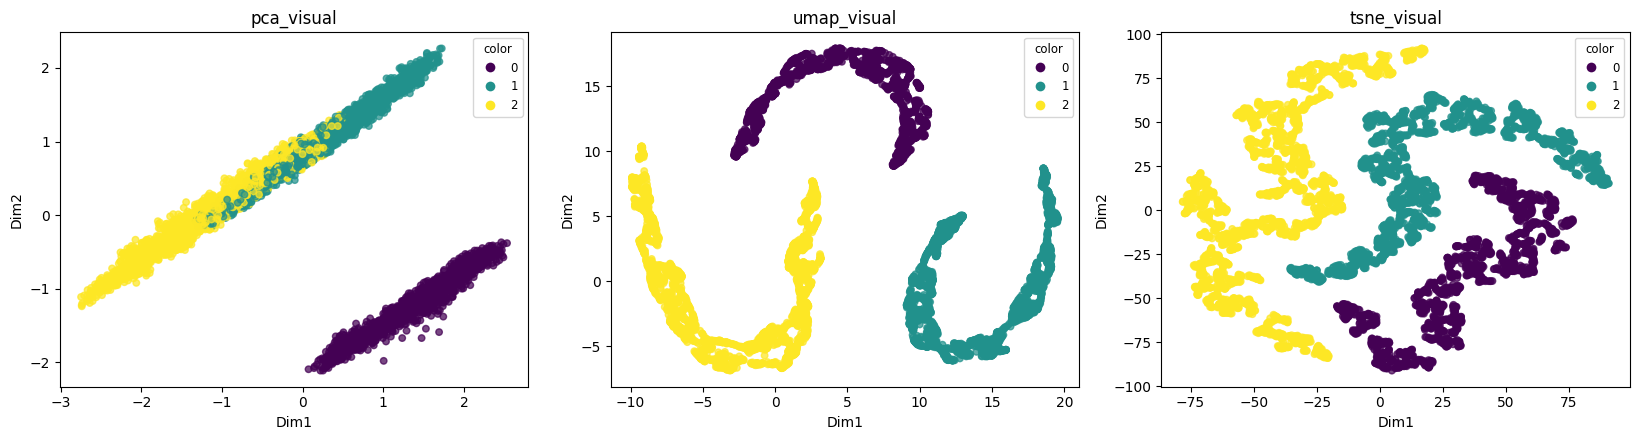

,embedding,method,n_components,variance_explained,parameters,purpose,status
0,pca_visual,pca,2,0.8903,"svd_solver=auto, whiten=False, random_state=None",visualization,created
1,pca_model,pca,3,1.0000,"svd_solver=auto, whiten=False, random_state=None",clustering candidate,created
2,umap_visual,umap,2,NaN,"n_neighbors=15, min_dist=0.1, metric=euclidean, random_state=None",visualization / local structure,created
3,tsne_visual,tsne,2,NaN,"perplexity=20, learning_rate=auto, max_iter=1000, init=pca, metric=euclidean, random_state=None",visualization / local structure,created


In [11]:
exploration = uns.explore(
    methods=("pca", "umap", "tsne"),
    pca_model_variance=0.90,

    umap_params={
        "n_neighbors": 15,
        "min_dist": 0.1,
        "metric": "euclidean",
    },

    tsne_params={
        "perplexity": 20,
        "learning_rate": "auto",
        "max_iter": 1000,
        "init": "pca",
        "metric": "euclidean",
    },

    color_by="color",
    legend=True,
    plot=True
)

exp = exploration["report"]

with pd.option_context(
    "display.max_colwidth", None,
    "display.width", 200
):
    display(exp)

In [12]:
comparison = uns.compare_spaces(
    spaces=[
        "feature_space",
        "pca_model",
        "umap_visual"
    ],
    method="kmeans",
    k_range=range(2, 11),
    n_init=150,
    max_iter=750,
    tol=1e-4
)

comparison["leaderboard"]


========== SPACE COMPARISON INTERPRETATION ==========
Signals:
  • El espacio mejor posicionado por métricas internas es 'feature_space' con k=5, silhouette=0.600 y Davies-Bouldin=0.532.
  • Los espacios no coinciden en la granularidad óptima; los k sugeridos fueron [5, 10].
  • No se proporcionó validation_label, por lo que la comparación se basa únicamente en métricas internas.
Recommended checks:
  • Validar estabilidad, tamaños de cluster, perfiles y utilidad de negocio antes de seleccionar la solución final.
  • La representación con mejor ranking no debe elegirse solo por verse mejor; debe confirmarse con estabilidad e interpretabilidad.


,space,method,best_k,silhouette,calinski_harabasz,davies_bouldin,inertia,n_iter,converged,consensus_rank
0,feature_space,kmeans,5,0.599907,10019.735986,0.532088,2134.519355,6,True,2.666667
1,pca_model,kmeans,5,0.599907,10019.735986,0.532088,2134.520868,7,True,2.666667
2,umap_visual,kmeans,10,0.516359,11455.093292,0.646238,37994.507812,9,True,1.666667


# validamos sin usar el color

In [13]:
uns = UnsupervisedAnalysis(
    df,
    validation_label="color"
)

uns.prepare(
    scale_num="auto",
    cat_encoding="auto"
)

========== UNSUPERVISED PREPROCESSING PLAN ==========
Numeric: {'standard': ['x', 'y'], 'robust': []}
Categorical: {}
Excluded: None
Output shape: (5710, 2)


{'X_embed':              x         y
 0     1.754000  0.786674
 1    -0.962171  0.760593
 2    -0.007283  0.421419
 3     1.390576  0.161016
 4    -0.468679 -0.493324
 ...        ...       ...
 5705 -0.342479  1.575415
 5706  1.363670  0.410259
 5707 -1.441652 -0.210868
 5708 -0.750371 -0.946331
 5709 -1.118721 -1.638908
 
 [5710 rows x 2 columns],
 'validation_label': 0       1
 1       0
 2       2
 3       1
 4       2
        ..
 5705    0
 5706    1
 5707    0
 5708    2
 5709    2
 Name: color, Length: 5710, dtype: int64,
 'y': 0       1
 1       0
 2       2
 3       1
 4       2
        ..
 5705    0
 5706    1
 5707    0
 5708    2
 5709    2
 Name: color, Length: 5710, dtype: int64,
 'ids': None,
 'feature_names_embed': ['x', 'y'],
 'preprocessor_embed': ColumnTransformer(transformers=[('num_standard',
                                  Pipeline(steps=[('imputer',
                                                   SimpleImputer(strategy='median')),
                            

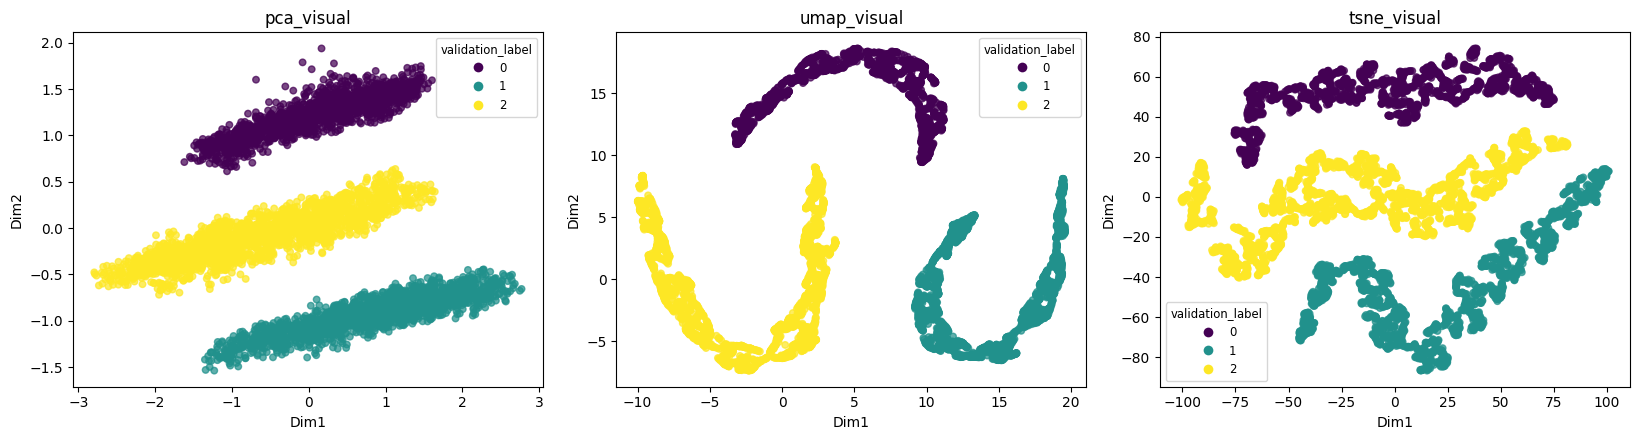

,embedding,method,n_components,variance_explained,parameters,purpose,status
0,pca_visual,pca,2,1.0,"svd_solver=auto, whiten=False, random_state=None",visualization,created
1,pca_model,pca,2,1.0,"svd_solver=auto, whiten=False, random_state=None",clustering candidate,created
2,umap_visual,umap,2,NaN,"n_neighbors=15, min_dist=0.1, metric=euclidean, random_state=None",visualization / local structure,created
3,tsne_visual,tsne,2,NaN,"perplexity=20, learning_rate=auto, max_iter=1000, init=pca, metric=euclidean, random_state=None",visualization / local structure,created


In [14]:
exploration = uns.explore(
    methods=("pca", "umap", "tsne"),
    pca_model_variance=0.90,

    umap_params={
        "n_neighbors": 15,
        "min_dist": 0.1,
        "metric": "euclidean",
    },

    tsne_params={
        "perplexity": 20,
        "learning_rate": "auto",
        "max_iter": 1000,
        "init": "pca",
        "metric": "euclidean",
    },

    color_by="validation_label",
    plot=True
)

exp = exploration["report"]

with pd.option_context(
    "display.max_colwidth", None,
    "display.width", 200
):
    display(exp)

In [16]:
comparison = uns.compare_spaces(
    spaces=[
        "feature_space",
        "pca_model",
        "umap_visual"
    ],
    method="kmeans",
    k_range=range(2, 11),
    n_init=150,
    max_iter=750,
    tol=1e-4
)

comparison["leaderboard"]


========== SPACE COMPARISON INTERPRETATION ==========
Signals:
  • El espacio mejor posicionado por métricas internas es 'umap_visual' con k=9, silhouette=0.525 y Davies-Bouldin=0.646.
  • Los espacios no coinciden en la granularidad óptima; los k sugeridos fueron [9, 10].
  • La solución interna no coincide con las 3 clases conocidas de 'color'. Esto puede indicar subestructura real, sobresegmentación o diferentes niveles válidos de granularidad.
  • La homogeneidad es alta pero la completitud es baja: los clusters son puros respecto a la etiqueta, pero cada clase conocida fue fragmentada en varios subclusters.
  • ARI=0.407: la partición interna difiere sustancialmente de la etiqueta conocida.
  • V-measure=0.667, resumen del balance entre homogeneidad y completitud.
Recommended checks:
  • Comparar explícitamente k=3 contra k=9 antes de elegir la granularidad final.
  • No usar la etiqueta de validación para entrenar; emplearla únicamente para contrastar e interpretar la solución.


,space,method,best_k,silhouette,calinski_harabasz,davies_bouldin,inertia,n_iter,converged,consensus_rank,validation_label,validation_n_classes,k_matches_validation,adjusted_rand_index,normalized_mutual_info,homogeneity,completeness,v_measure
0,umap_visual,kmeans,9,0.524687,10861.624243,0.646230,46828.714844,8,True,2.000000,color,3,False,0.407315,0.667135,1.0,0.500527,0.667135
1,feature_space,kmeans,10,0.504269,10902.634115,0.596757,626.980287,9,True,1.666667,color,3,False,0.365485,0.645042,1.0,0.476060,0.645042
2,pca_model,kmeans,10,0.503864,10902.460271,0.597247,626.995720,16,True,1.666667,color,3,False,0.365797,0.645150,1.0,0.476178,0.645150


# Comparaciones

In [17]:
recommendations = uns.recommend_cluster_models(
    space="umap_visual"
)

with pd.option_context(
    "display.max_colwidth", None,
    "display.width", 200
):
    display(recommendations)

,space,model,priority_score,available,reason,family
0,umap_visual,kmeans,4.0,True,escala bien a muchas filas; espacio de baja dimensión; baseline interpretable,centroid
1,umap_visual,gaussian_mixture,2.0,True,covarianzas estimables; evalúa pertenencia probabilística,probabilistic
2,umap_visual,dbscan,1.0,True,muestra suficiente para explorar densidad,density
3,umap_visual,hdbscan,1.0,True,puede explorar densidades variables,density
4,umap_visual,kmedoids,0.0,True,modelo complementario,medoid
5,umap_visual,agglomerative,0.0,True,modelo complementario,hierarchical


In [18]:
experiment = uns.build_experiment(
    models="recommended",
    k_range=range(2, 11),
    evaluate_stability=True,
    n_stability_runs=5,
    n_init=50,
    max_iter=500,
    tol=1e-4,
    random_state=None
)

========== CLUSTERING EXPERIMENT PLAN ==========


,step,role,model,priority_label,available,reason,experiment_purpose
0,1,baseline,kmeans,High,True,escala bien a muchas filas • espacio de baja dimensión • baseline interpretable,"Establish a fast, interpretable centroid benchmark."
1,2,robust alternative,kmedoids,Low,True,modelo complementario,Test a medoid solution that is less sensitive to extreme observations.
2,3,hierarchical alternative,agglomerative,Low,True,modelo complementario,Test whether a nested or linkage-based structure better represents the sample.
3,4,probabilistic alternative,gaussian_mixture,Recommended,True,covarianzas estimables • evalúa pertenencia probabilística,Test elliptical clusters and soft membership probabilities.
4,5,density/noise diagnostic,dbscan,Exploratory,True,muestra suficiente para explorar densidad,Test irregular shapes and whether isolated observations should be treated as noise.
5,6,variable-density diagnostic,hdbscan,Exploratory,True,puede explorar densidades variables,Explore density-varying groups and noise without fixing k.


Note: this is a test plan, not a model ranking. Use plan.run() for the competition.


In [19]:
competition = experiment.run()

========== CLUSTERING COMPETITION ==========


,rank,space,model,params,n_clusters,silhouette,calinski_harabasz,davies_bouldin,stability_ari,noise_pct,min_cluster_pct,competition_score
0,1,umap_visual,kmeans,"{'k': 3, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, '...",3,0.543074,8545.546909,0.662603,1.000000,0.0,30.805604,11.0
1,2,umap_visual,gaussian_mixture,"{'k': 3, 'covariance_type': 'full', 'n_init': 10, 'max_i...",3,0.536374,8233.280524,0.671518,1.000000,0.0,27.880911,13.6
2,3,umap_visual,agglomerative,"{'k': 3, 'linkage': 'ward', 'metric': 'euclidean'}",3,0.535606,8200.159354,0.672895,1.000000,0.0,27.723292,14.4
3,4,umap_visual,agglomerative,"{'k': 3, 'linkage': 'complete', 'metric': 'euclidean'}",3,0.535606,8200.159354,0.672895,1.000000,0.0,27.723292,14.4
4,5,umap_visual,agglomerative,"{'k': 3, 'linkage': 'average', 'metric': 'euclidean'}",3,0.535606,8200.159354,0.672895,1.000000,0.0,27.723292,14.4
5,6,umap_visual,hdbscan,"{'min_cluster_size': 75, 'min_samples': None}",3,0.535606,8200.159354,0.672895,1.000000,0.0,27.723292,14.4
6,7,umap_visual,agglomerative,"{'k': 10, 'linkage': 'ward', 'metric': 'euclidean'}",10,0.530294,11006.228315,0.614973,1.000000,0.0,4.290718,16.4
7,8,umap_visual,agglomerative,"{'k': 10, 'linkage': 'average', 'metric': 'euclidean'}",10,0.517786,10454.883667,0.587376,1.000000,0.0,4.290718,17.8
8,9,umap_visual,gaussian_mixture,"{'k': 3, 'covariance_type': 'diag', 'n_init': 10, 'max_i...",3,0.534032,8155.618222,0.674234,1.000000,0.0,27.355517,18.0
9,10,umap_visual,kmedoids,"{'k': 3, 'metric': 'euclidean', 'max_iter': 500, 'random...",3,0.542949,8544.506056,0.662580,0.997722,0.0,30.963222,18.4


In [24]:
comp = competition.candidates(valid_only=True)

comp_sorted = comp.sort_values(
    ["silhouette", "calinski_harabasz"],
    ascending=[False, False]
)

with pd.option_context(
    "display.max_colwidth", None,
    "display.width", 200
):
    display(comp_sorted.head(3))


,space,model,params,n_clusters,n_noise,noise_pct,min_cluster_pct,silhouette,calinski_harabasz,davies_bouldin,stability_ari,inertia,aic,bic,n_iter,converged,valid,error
1,umap_visual,kmeans,"{'k': 3, 'n_init': 50, 'max_iter': 500, 'tol': 0.0001, 'random_state': None}",3,0,0.0,30.805604,0.543074,8545.546909,0.662603,1.000000,190393.6875,NaN,NaN,6.0,True,True,None
11,umap_visual,kmedoids,"{'k': 3, 'metric': 'euclidean', 'max_iter': 500, 'random_state': None}",3,0,0.0,30.963222,0.542949,8544.506056,0.662580,0.997722,NaN,NaN,NaN,NaN,True,True,None
12,umap_visual,kmedoids,"{'k': 3, 'metric': 'manhattan', 'max_iter': 500, 'random_state': None}",3,0,0.0,31.436077,0.542627,8536.101450,0.662622,0.836660,NaN,NaN,NaN,NaN,True,True,None


In [25]:
solution = competition.fit_best(
    name="basic3_segments"
)

In [26]:
solution.summary()

,solution,method,X_used,k,inertia,n_iter,max_iter,converged,n_init,init,tol,algorithm,random_state,silhouette,calinski_harabasz,davies_bouldin,n_clusters,n_noise
0,basic3_segments,kmeans,umap_visual,3,190393.6875,6,500,True,50,k-means++,0.0001,lloyd,None,0.543074,8545.546909,0.662603,3,0


In [28]:

clust_df =solution.dataset()
clust_df['cluster'].value_counts()

cluster
2    2128
0    1823
1    1759
Name: count, dtype: int64

c:\Users\chefv\OneDrive\Documents\Data Science\DataScience_Class.py:4410: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



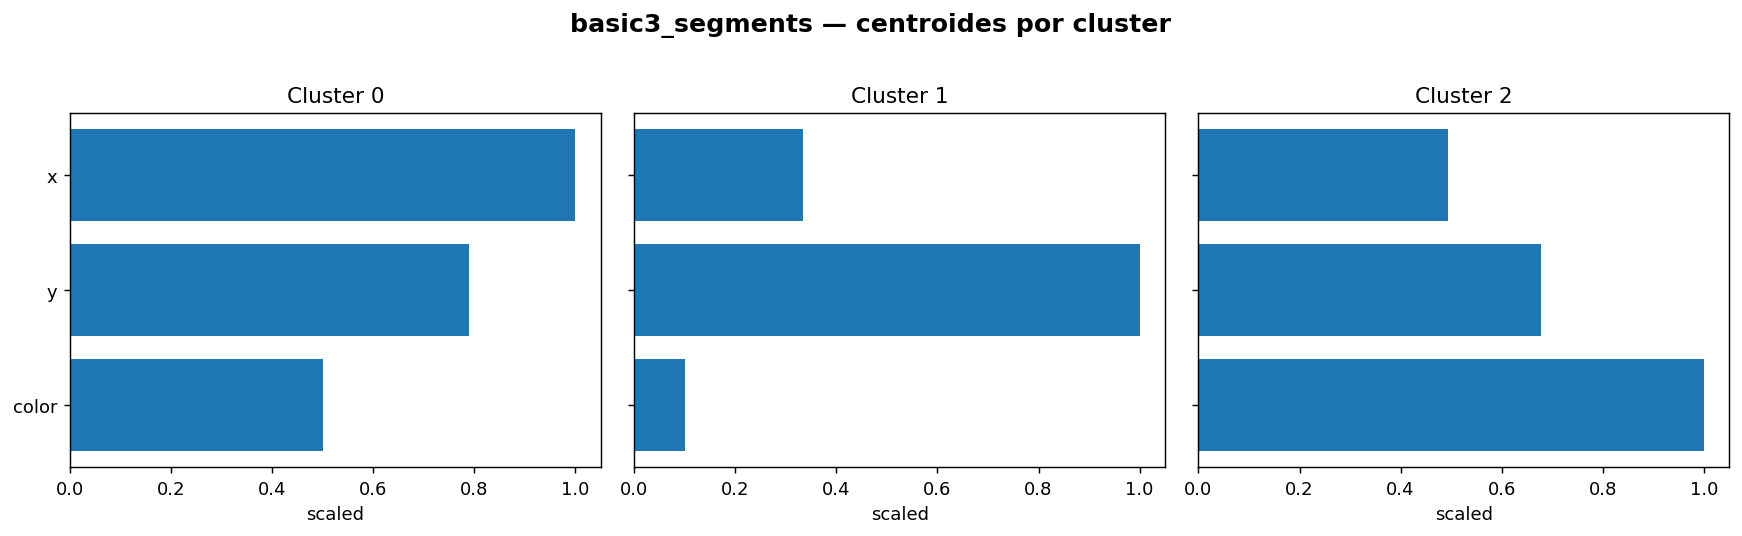

c:\Users\chefv\OneDrive\Documents\Data Science\DataScience_Class.py:4410: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



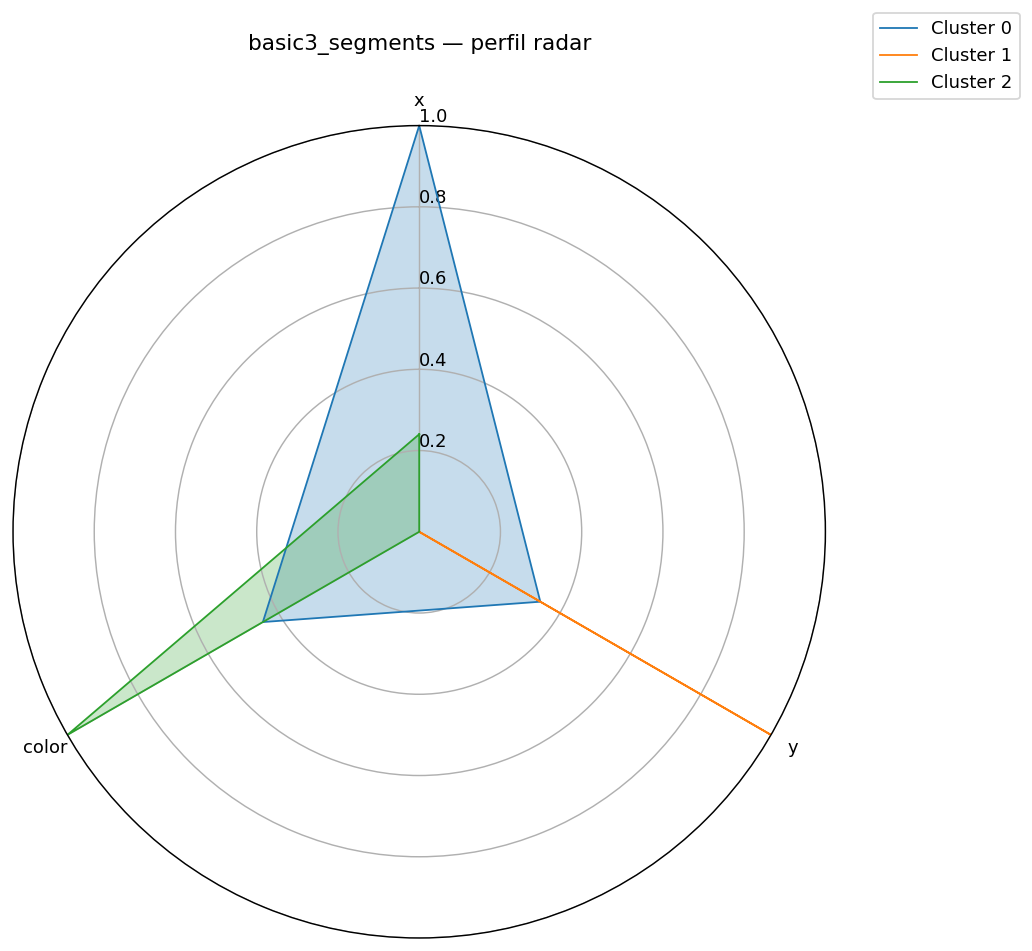

In [29]:

solution.plot_cluster_bars(normalize=True)
solution.plot_cluster_radar(normalize="minmax")

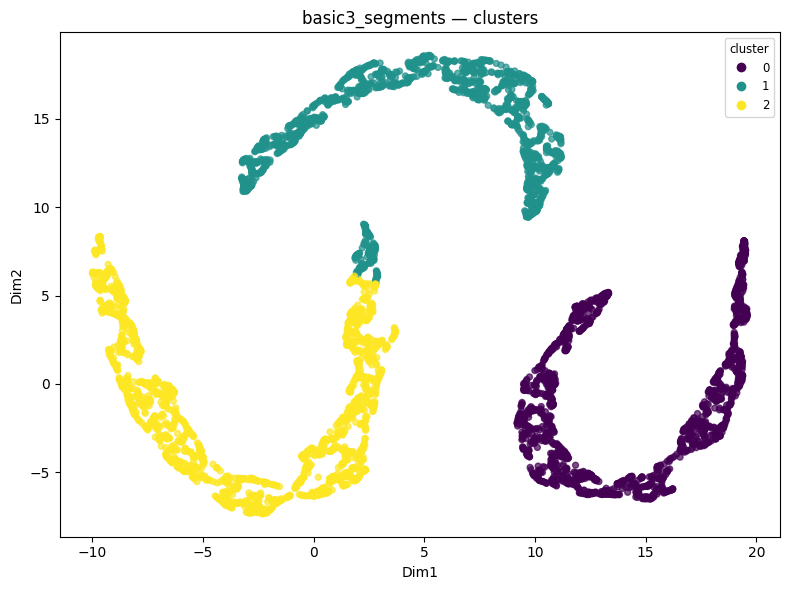

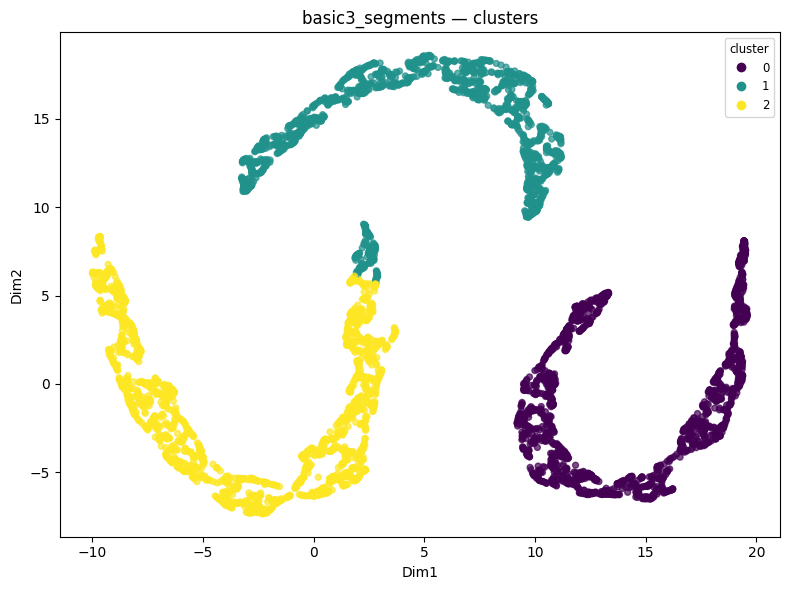

In [30]:
solution.plot(
    embedding="umap_visual",
    save=False
)

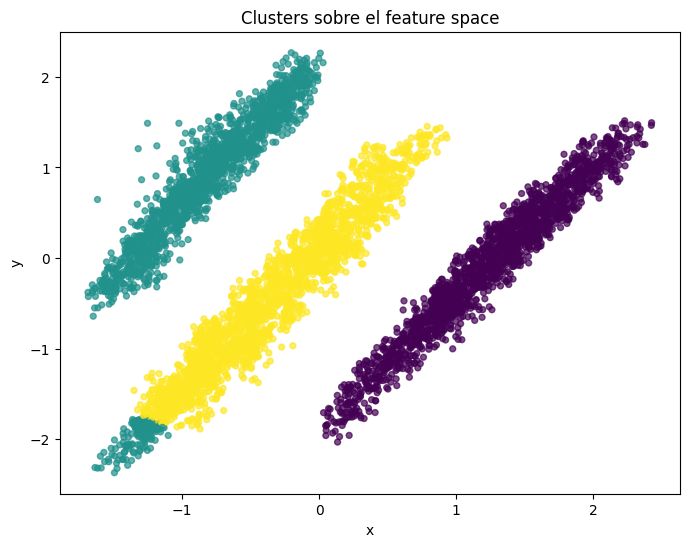

In [32]:
X_original = uns.X_embed_

plt.figure(figsize=(8, 6))

plt.scatter(
    X_original.iloc[:, 0],
    X_original.iloc[:, 1],
    c=solution["labels"],
    cmap="viridis",
    alpha=0.7,
    s=18
)

plt.xlabel(X_original.columns[0])
plt.ylabel(X_original.columns[1])
plt.title("Clusters sobre el feature space")
plt.show()